# Exploración del conjunto de datos de enfermedades cardíacas

En este cuaderno se analiza la estructura, la calidad y la distribución inicial de los datos clínicos antes de construir cualquier modelo. Solo se explora el dataset: no se normaliza, no se limpia y no se entrena nada.

## 1. Importación de librerías

Se cargan las librerías para manejar tablas (pandas), hacer cálculos (numpy) y dibujar gráficos (matplotlib y seaborn).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.labelsize"] = 10

print("Librerías importadas correctamente")

Librerías importadas correctamente


**Interpretación del resultado**

Las librerías se importaron sin errores. Con pandas se leerá y resumirá la tabla, y con matplotlib y seaborn se dibujarán los gráficos con un estilo de fondo claro y cuadrícula suave. No se importó ninguna librería de modelado porque esta fase es solo exploratoria.

## 2. Carga del dataset

Se lee el archivo `heart.csv` con pandas y se guarda en la variable `df`. Este archivo no se modificará en ningún momento.

In [2]:
df = pd.read_csv("../data/heart.csv")

print("Dataset cargado correctamente")
print("Archivo: ../data/heart.csv")

Dataset cargado correctamente
Archivo: ../data/heart.csv


**Interpretación del resultado**

La lectura del archivo terminó sin errores, por lo que la ruta es correcta y los datos ya están en memoria dentro del objeto `df`. A partir de aquí todos los resultados salen de esta tabla, sin escribir ningún valor a mano.

## 3. Primeras filas del dataset

Se muestran las primeras 5 filas para ver cómo está organizada la información de cada paciente.

In [3]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


**Interpretación del resultado**

Cada fila corresponde a un registro clínico y cada columna a una variable. Todos los valores son numéricos, incluso los que representan categorías (por ejemplo `sex` o `cp`), y la última columna, `target`, contiene el resultado que se quiere clasificar. Esta vista solo sirve para reconocer el formato; el análisis detallado viene en las siguientes secciones.

## 4. Dimensiones del dataset

Se cuenta cuántas filas (registros) y cuántas columnas (variables) tiene la tabla.

In [4]:
filas, columnas = df.shape
print(f"{filas} registros × {columnas} variables")

1025 registros × 14 variables


**Interpretación del resultado**

El dataset tiene 1025 registros y 14 variables. De estas 14 columnas, 13 son variables predictoras (datos clínicos del paciente) y 1 es la variable objetivo `target`. Son datos de tipo tabular con un tamaño moderado, suficiente para una exploración completa sin problemas de memoria.

## 5. Nombres de las variables

Se listan las 14 columnas y se explica en español qué representa cada una.

In [5]:
print(list(df.columns))

descripcion = pd.DataFrame({
    "Variable": df.columns,
    "Significado": [
        "edad",
        "sexo",
        "tipo de dolor de pecho",
        "presión arterial en reposo",
        "colesterol sérico",
        "glucemia en ayunas",
        "resultado del electrocardiograma en reposo",
        "frecuencia cardíaca máxima alcanzada",
        "angina inducida por ejercicio",
        "depresión del segmento ST",
        "pendiente del segmento ST",
        "número de vasos principales",
        "resultado de talasemia",
        "presencia o ausencia de enfermedad cardíaca (variable objetivo)",
    ],
})
descripcion

['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


,Variable,Significado
0,age,edad
1,sex,sexo
2,cp,tipo de dolor de pecho
3,trestbps,presión arterial en reposo
4,chol,colesterol sérico
5,fbs,glucemia en ayunas
6,restecg,resultado del electrocardiograma en reposo
7,thalach,frecuencia cardíaca máxima alcanzada
8,exang,angina inducida por ejercicio
9,oldpeak,depresión del segmento ST


**Interpretación del resultado**

Las columnas coinciden exactamente con las 14 esperadas y se conservaron sus nombres originales. Las primeras 13 describen al paciente y sus pruebas clínicas; `target` es la **variable objetivo**, es decir, lo que el modelo deberá aprender a predecir más adelante.

## 6. Tipos de datos

Con `df.info()` se revisa el tipo de dato de cada columna y cuántos valores no nulos tiene. No se convierte ningún tipo en esta fase.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


**Interpretación del resultado**

Las 14 columnas tienen 1025 valores no nulos. Trece variables son enteras (`int64`) y solo `oldpeak` es decimal (`float64`). Varias variables enteras como `sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `ca` y `thal` en realidad son códigos de categorías, algo que se tendrá presente en el preprocesamiento.

## 7. Valores faltantes

Se cuenta, columna por columna, cuántas celdas están vacías.

In [7]:
faltantes = df.isnull().sum()
print(faltantes)
print()
print("Total de valores faltantes:", faltantes.sum())

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Total de valores faltantes: 0


**Interpretación del resultado**

Cada columna muestra 0 valores faltantes y el total es 0. Esto indica que el dataset está completo y que no hará falta imputar ni eliminar filas por datos vacíos, lo que es una buena señal para la calidad inicial de los datos.

## 8. Registros duplicados

Se cuentan las filas que son exactamente iguales a otra fila anterior. Solo se identifican: no se elimina ninguna.

In [8]:
n_duplicados = df.duplicated().sum()
print("Filas duplicadas exactas:", n_duplicados)
print("Porcentaje del total: {:.1f}%".format(100 * n_duplicados / len(df)))
print("Dimensiones de df después de la comprobación:", df.shape)

Filas duplicadas exactas: 723
Porcentaje del total: 70.5%
Dimensiones de df después de la comprobación: (1025, 14)


**Interpretación del resultado**

Se detectaron 723 filas duplicadas exactas, alrededor del 70.5 % del total. En esta fase únicamente se identifican y documentan: `df` sigue teniendo 1025 filas. La decisión sobre cómo tratarlas se tomará más adelante, en el preprocesamiento, porque puede influir en los resultados del modelo.

## 9. Variable objetivo

Se analiza `target`: cuántos registros hay en cada clase, qué porcentaje representan y cómo se ven en un gráfico de barras.

        Frecuencia  Porcentaje (%)
target                            
0              499           48.68
1              526           51.32


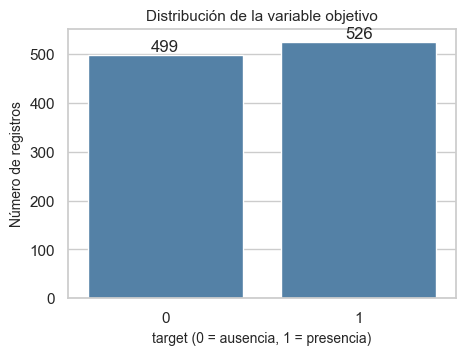

In [9]:
frecuencia = df["target"].value_counts().sort_index()
porcentaje = (df["target"].value_counts(normalize=True).sort_index() * 100).round(2)
tabla_target = pd.DataFrame({"Frecuencia": frecuencia, "Porcentaje (%)": porcentaje})
print(tabla_target)

plt.figure(figsize=(5, 3.5))
ax = sns.countplot(x="target", data=df, color="steelblue")
ax.bar_label(ax.containers[0])
plt.title("Distribución de la variable objetivo")
plt.xlabel("target (0 = ausencia, 1 = presencia)")
plt.ylabel("Número de registros")
plt.show()

**Interpretación del resultado**

Hay 499 registros con `target = 0` (ausencia de enfermedad cardíaca) y 526 con `target = 1` (presencia), es decir, 48.68 % y 51.32 %. Las dos clases están casi equilibradas, por lo que no hay un problema de desbalance fuerte. Es una clasificación binaria de presencia o ausencia: el dataset no indica qué enfermedad cardíaca específica tiene cada paciente.

## 10. Estadísticas descriptivas

Con `df.describe()` se obtiene un resumen numérico de cada variable.

In [10]:
df.describe().round(2)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00
mean,54.43,0.70,0.94,131.61,246.00,0.15,0.53,149.11,0.34,1.07,1.39,0.75,2.32,0.51
std,9.07,0.46,1.03,17.52,51.59,0.36,0.53,23.01,0.47,1.18,0.62,1.03,0.62,0.50
min,29.00,0.00,0.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,48.00,0.00,0.00,120.00,211.00,0.00,0.00,132.00,0.00,0.00,1.00,0.00,2.00,0.00
50%,56.00,1.00,1.00,130.00,240.00,0.00,1.00,152.00,0.00,0.80,1.00,0.00,2.00,1.00
75%,61.00,1.00,2.00,140.00,275.00,0.00,1.00,166.00,1.00,1.80,2.00,1.00,3.00,1.00
max,77.00,1.00,3.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,2.00,4.00,3.00,1.00


**Interpretación del resultado**

**count** es el número de valores (1025 en todas), **mean** el promedio, **std** qué tanto se dispersan los datos, **min** y **max** los extremos, y **25 %**, **50 %** y **75 %** los cuartiles (el 50 % es la mediana). Se observa que las variables están en escalas muy distintas: `chol` va de 126 a 564 mientras que `oldpeak` va de 0 a 6.2. Aquí solo se describen los números, sin valorarlos clínicamente.

## 11. Distribución de las variables numéricas

Se dibujan histogramas de las variables numéricas continuas para ver cómo se reparten sus valores.

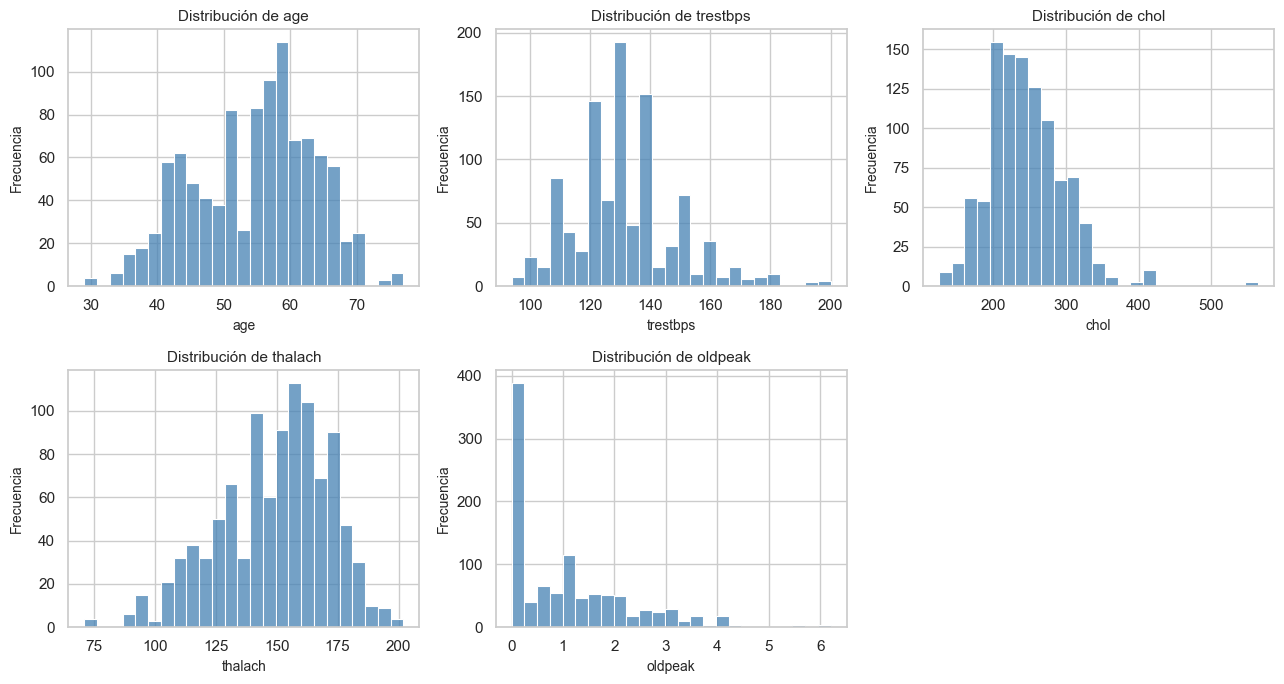

Asimetría (skewness):
age        -0.25
trestbps    0.74
chol        1.07
thalach    -0.51
oldpeak     1.21
dtype: float64


In [11]:
continuas = ["age", "trestbps", "chol", "thalach", "oldpeak"]

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
axes = axes.flatten()
for i, col in enumerate(continuas):
    sns.histplot(df[col], bins=25, color="steelblue", ax=axes[i])
    axes[i].set_title("Distribución de " + col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frecuencia")
axes[5].axis("off")
plt.tight_layout()
plt.show()

print("Asimetría (skewness):")
print(df[continuas].skew().round(2))

**Interpretación del resultado**

`age` y `thalach` están repartidas de forma bastante amplia, con una asimetría leve (-0.25 y -0.51). `chol` (1.07) y `oldpeak` (1.21) tienen cola larga hacia la derecha: por ejemplo, el máximo de `chol` es 564 mientras que el 75 % de los registros está por debajo de 275. En `oldpeak` al menos una cuarta parte de los registros vale 0. `trestbps` también presenta una cola derecha moderada (0.74).

## 12. Variables categóricas

Se cuenta cuántos registros hay en cada categoría de las variables discretas, sin transformarlas todavía.

sex {0: 312, 1: 713}
cp {0: 497, 1: 167, 2: 284, 3: 77}
fbs {0: 872, 1: 153}
restecg {0: 497, 1: 513, 2: 15}
exang {0: 680, 1: 345}
slope {0: 74, 1: 482, 2: 469}
ca {0: 578, 1: 226, 2: 134, 3: 69, 4: 18}
thal {0: 7, 1: 64, 2: 544, 3: 410}
target {0: 499, 1: 526}


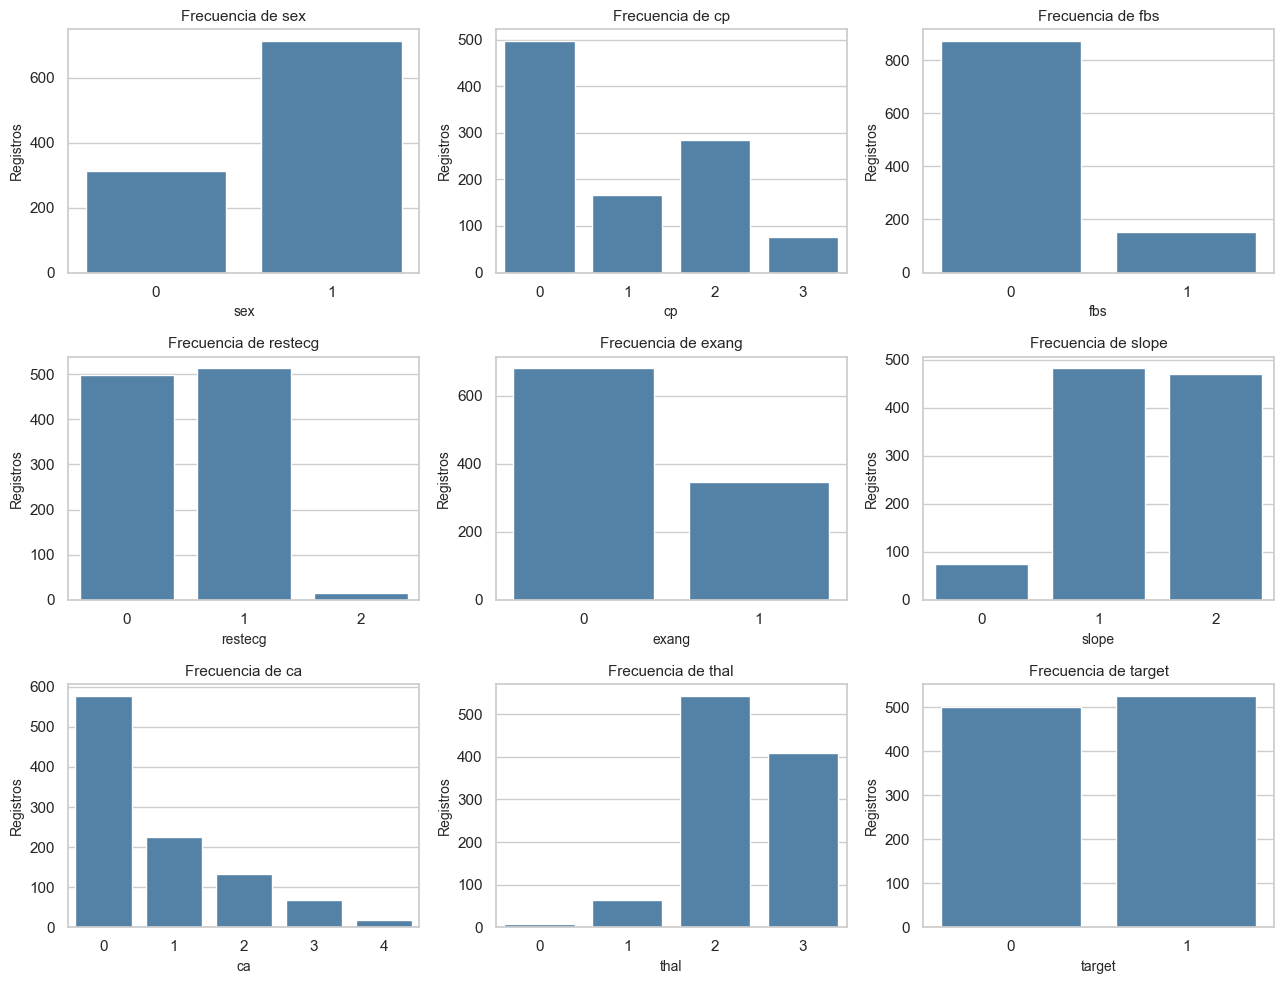

In [12]:
categoricas = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal", "target"]

for col in categoricas:
    print(col, df[col].value_counts().sort_index().to_dict())

fig, axes = plt.subplots(3, 3, figsize=(13, 10))
axes = axes.flatten()
for i, col in enumerate(categoricas):
    sns.countplot(x=col, data=df, color="steelblue", ax=axes[i])
    axes[i].set_title("Frecuencia de " + col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Registros")
plt.tight_layout()
plt.show()

**Interpretación del resultado**

Algunas categorías dominan: en `sex` hay 713 registros con valor 1 frente a 312 con valor 0, y en `fbs` hay 872 con valor 0 frente a 153 con valor 1. `cp` tiene 4 categorías y la 0 es la más frecuente (497). Hay categorías muy poco representadas, como `restecg = 2` (15 registros), `thal = 0` (7) y `ca = 4` (18). Todas estas variables siguen codificadas como números; no se aplicó ninguna codificación.

## 13. Correlación entre variables

Se calcula la correlación entre todas las variables y se muestra en un mapa de calor para explorar qué variables se mueven juntas.

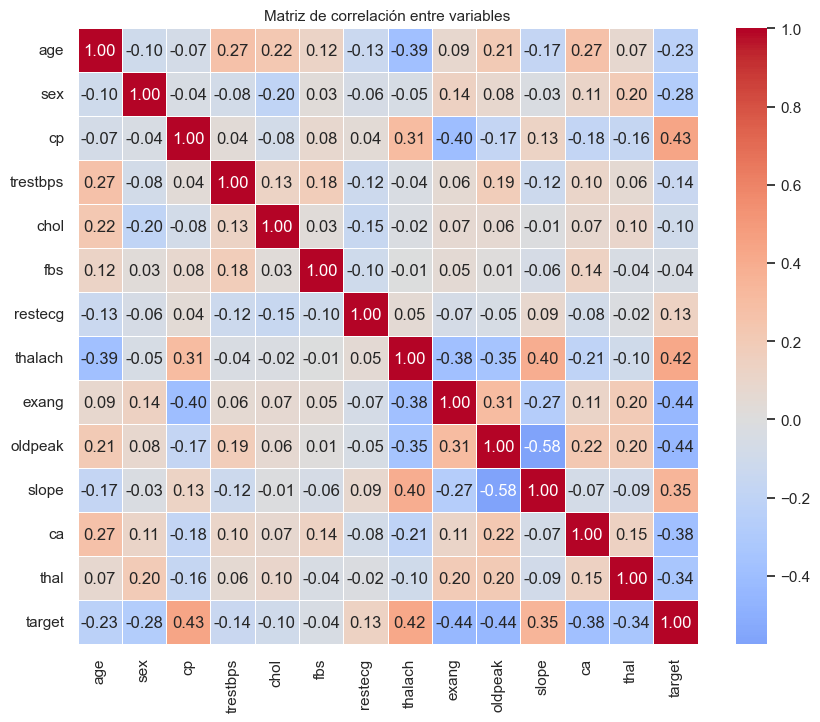

Correlación de cada variable con target:
oldpeak    -0.438
exang      -0.438
ca         -0.382
thal       -0.338
sex        -0.280
age        -0.229
trestbps   -0.139
chol       -0.100
fbs        -0.041
restecg     0.134
slope       0.346
thalach     0.423
cp          0.435
Name: target, dtype: float64


In [13]:
correlacion = df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Matriz de correlación entre variables")
plt.show()

print("Correlación de cada variable con target:")
print(correlacion["target"].drop("target").sort_values().round(3))

**Interpretación del resultado**

Las correlaciones más fuertes con `target` son moderadas: `cp` (0.435), `thalach` (0.423) y `slope` (0.346) positivas, y `oldpeak` (-0.438), `exang` (-0.438), `ca` (-0.382) y `thal` (-0.338) negativas. Ninguna llega a valores cercanos a 1, así que ninguna variable por sí sola explica la clase. Una correlación solo indica que dos variables varían juntas; no demuestra que una cause la enfermedad cardíaca.

## 14. Relación entre variables y target

Se comparan con diagramas de caja los valores de algunas variables clínicas entre los registros con `target = 0` y `target = 1`.

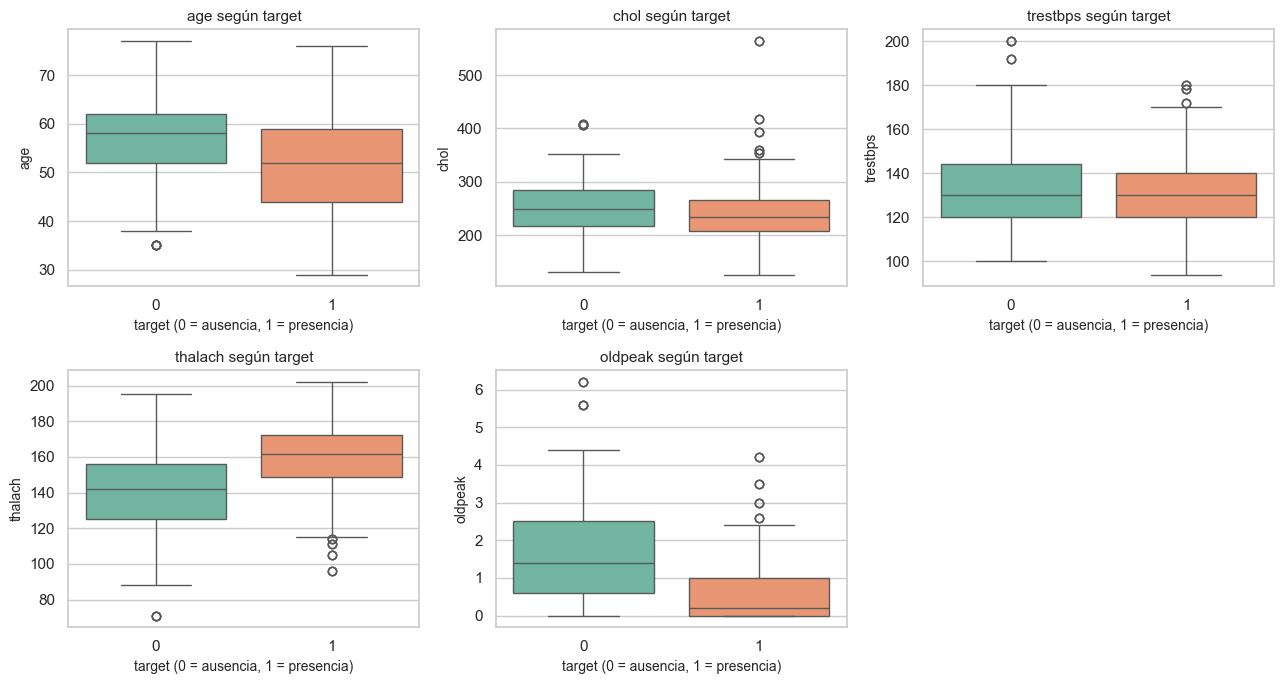

age           chol        trestbps        thalach        oldpeak  \
         mean median    mean median     mean median    mean median    mean   
target                                                                       
0       56.57   58.0  251.29  249.0   134.11  130.0  139.13  142.0    1.60   
1       52.41   52.0  240.98  234.0   129.25  130.0  158.59  161.5    0.57   

               
       median  
target         
0         1.4  
1         0.2

In [14]:
variables = ["age", "chol", "trestbps", "thalach", "oldpeak"]

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
axes = axes.flatten()
for i, col in enumerate(variables):
    sns.boxplot(x="target", y=col, data=df, hue="target", palette="Set2", legend=False, ax=axes[i])
    axes[i].set_title(col + " según target")
    axes[i].set_xlabel("target (0 = ausencia, 1 = presencia)")
    axes[i].set_ylabel(col)
axes[5].axis("off")
plt.tight_layout()
plt.show()

df.groupby("target")[variables].agg(["mean", "median"]).round(2)

**Interpretación del resultado**

La mayor diferencia entre grupos aparece en `thalach` (media de 139.13 con `target = 0` y 158.59 con `target = 1`) y en `oldpeak` (1.60 frente a 0.57). `age` es algo menor en `target = 1` (52.41 frente a 56.57). En `chol` (251.29 y 240.98) y `trestbps` (134.11 y 129.25) las diferencias son pequeñas y los rangos se solapan bastante. Son diferencias observadas en estos datos, no un criterio de diagnóstico.

## Resumen de los principales hallazgos

- El dataset tiene **1025 registros** y **14 variables**: 13 predictoras y 1 objetivo (`target`).
- No hay **valores faltantes** en ninguna columna.
- Hay **723 registros duplicados exactos** (alrededor del 70.5 %), que se documentaron pero no se eliminaron.
- La variable objetivo es casi balanceada: **499** registros con `target = 0` y **526** con `target = 1`.
- Trece variables son enteras y solo `oldpeak` es decimal; varias enteras son en realidad categorías codificadas.
- Las variables tienen escalas muy distintas (por ejemplo `chol` de 126 a 564 y `oldpeak` de 0 a 6.2).
- `chol` y `oldpeak` muestran cola larga hacia la derecha.
- Algunas categorías son poco frecuentes: `restecg = 2` (15), `thal = 0` (7) y `ca = 4` (18).
- Las correlaciones con `target` son moderadas (máximo en valor absoluto: 0.438), y `thalach` y `oldpeak` son las variables con mayor diferencia entre las dos clases.

## Conclusión de esta fase

El dataset está estructurado y disponible para continuar: tiene 1025 registros, 14 variables bien identificadas y no presenta valores faltantes. Contiene 723 filas duplicadas exactas que deberán considerarse en el preprocesamiento. La variable objetivo `target` permite plantear una clasificación binaria de presencia o ausencia de enfermedad cardíaca, con clases casi balanceadas.

En esta fase todavía no se realizó normalización ni entrenamiento, y el archivo original no fue modificado. El siguiente paso será el preprocesamiento de los datos.